# DeepONet UNISIM-I-D -- V1a/V1b (CNN branch + MLP trunk) -- Colab

**Technique:** DeepONet (neural operator). A dedicated `scmil-deeponet` skill does not exist yet; this notebook follows the general `scmil-core` conventions (`VERSION_ID`, `TECNICA_ID`, standard imports).

**Date:** 10/05/2026 -- V1a initial, V1b the same day (fix of the `Sw` range).

**Architecture:** see the tech-plan `deeponet-unisim1-arquitectura` (Traycer epic) and `SCMIL_UNISIM1_OPERADOR_NEURAL_DEEPONET_PLAN.md`. Summary:
- **Branch (CNN):** receives 5 channels `(x_hat, y_hat, logK_norm, bitmask(RATE_INJ1), bitmask(LRAT_NA2))` over the `81x58` grid of layer `k=2`. Produces the full spatial field `(Ncout=2, Nt=61, 81, 58)`.
- **Trunk (MLP):** receives the full vector of 61 normalized time steps (the same for the 50 scenarios), produces a weight vector `(61,)`.
- **Combination:** Hadamard product with *broadcasting* of the trunk over the branch -- this is not the classic DeepONet with an inner product reduced to `r` components.
- **Output:** `Sw(x,y,t)` and `P(x,y,t)` (dual, `Ncout=2`). Since V1b, the `Sw` channel goes through `sigmoid()` at the end (bounds it to `(0,1)`); `P` remains unconstrained.
- Reference: Santos et al. (2025), *Hybrid DeepONet Surrogates for Multiphase Flow in Porous Media*, arXiv:2511.02962.

**Prerequisite:** `unisim1_deeponet_dataset.h5` (114.8 MB) must be uploaded to Google Drive, under `MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/datasets/`. Checkpoints and summaries are saved to `MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/DeepONet/models/`. This notebook NEVER references a Windows path when running on Colab.

**History:**

| Version | Date | Change |
|---|---|---|
| V1a | 10/05/2026 | Initial version -- CNN branch, MLP trunk, k-fold (5), final retraining on the full 50 |
| V1b | 10/05/2026 | Fix of the `Sw` range: `sigmoid()` on the `Sw` channel of the final output (bounds it to `(0,1)`); `CELL 8` masks inactive cells before plotting (the colorbar no longer auto-scales to physically meaningless values). See Master MD Sec. 9 |

In [1]:
# -- CELL 1 - Imports, seed, device --
# === Scientific core ===
import numpy as np
import matplotlib.pyplot as plt

# === Data ===
import h5py
from pathlib import Path

# === Deep Learning ===
import torch
import torch.nn as nn

# === Interactivity ===
import ipywidgets as widgets
from ipywidgets import interact

# === Utilities ===
import json
import warnings
warnings.filterwarnings('ignore')

VERSION_ID = "V1b"
TECNICA_ID = "DeepONet"

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{TECNICA_ID} {VERSION_ID} -- device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

DeepONet V1b -- device: cuda
GPU: Tesla T4


## 1. Dataset loading (Drive on Colab, local as fallback)

Same environment-detection pattern as `SCMIL_03_UNISIM1_DeepONet_Exploracion50Escenarios.ipynb` -- on Colab it mounts Drive and reads from there; it never references `C:\...`.

In [2]:
# -- CELL 2 - Dataset loading (Drive on Colab, local as fallback) --
IN_COLAB = Path("/content").exists()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL")
    DATASET_PATH = BASE_DIR / "datasets" / "unisim1_deeponet_dataset.h5"
    OUTPUT_DIR = BASE_DIR / "DeepONet" / "models"
else:
    # Local fallback -- only if this notebook is run outside Colab.
    DATASET_PATH = Path(
        r"C:\Users\guita\Desktop\PhD-ScimL-New\Analisis de PINNS\Claude\OPM"
        r"\OPERADOR NEURAL\unisim1_deeponet_dataset.h5"
    )
    OUTPUT_DIR = DATASET_PATH.parent / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    extra = (
        "\nYou are on Colab: place unisim1_deeponet_dataset.h5 in "
        "'MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/datasets/'." if IN_COLAB else
        "\nAdjust DATASET_PATH if the file is in another local location."
    )
    raise FileNotFoundError(f"Could not find {DATASET_PATH}." + extra)

f = h5py.File(DATASET_PATH, "r")
permx = f["static/permx"][:]
permy = f["static/permy"][:]
actnum = f["static/actnum"][:].astype(bool)
params = f["scenarios/params"][:]          # (50, 2) -> [RATE_INJ1, LRAT_NA2]
time_days = f["scenarios/time_days"][:]    # (61,)
swat = f["scenarios/swat"][:]              # (50, 61, 81, 58)
pressure = f["scenarios/pressure"][:]      # (50, 61, 81, 58)
f.close()

NX, NY = actnum.shape
N_ESCENARIOS, N_T = swat.shape[0], swat.shape[1]
print(f"Environment: {'Colab' if IN_COLAB else 'local'}")
print(f"Grid: {NX}x{NY} | active cells: {actnum.sum()} ({100*actnum.mean():.1f}%)")
print(f"Scenarios: {N_ESCENARIOS} | snapshots: {N_T} (0 to {time_days[-1]/365.25:.2f} years)")

Mounted at /content/drive
Environment: Colab
Grid: 81x58 | active cells: 2296 (48.9%)
Scenarios: 50 | snapshots: 61 (0 to 5.00 years)


## 2. Preprocessing -- building the branch/trunk inputs

Branch: 5 channels `(x_hat, y_hat, logK_norm, bitmask(RATE_INJ1), bitmask(LRAT_NA2))`, identical in `x_hat`/`y_hat`/`logK` across the 50 scenarios (same `K`), different in the two bitmask channels (one per scenario). Inactive cells (`ACTNUM=0`) are set to `0`, not `NaN` -- the network cannot receive `NaN`; they are excluded from the loss via `mask`, not filled with a fake physical value.

In [3]:
# -- CELL 3 - Preprocessing: branch/trunk inputs and targets --
# Well positions (0-based), same as in the PINN and the exploratory notebook
INJ1_IJ = (9, 39)
NA2_IJ = (20, 35)

# LHS ranges (see SCMIL_UNISIM1_OPERADOR_NEURAL_DEEPONET_PLAN.md, Section 3)
RATE_INJ1_RANGE = (2000.0, 6000.0)
LRAT_NA2_RANGE = (1500.0, 4500.0)

# --- normalized coordinates ---
xg, yg = np.meshgrid(np.linspace(0, 1, NX), np.linspace(0, 1, NY), indexing="ij")
xg, yg = xg.astype(np.float32), yg.astype(np.float32)

# --- logK (geomean of permx/permy), normalized using only active-cell statistics ---
k_geo = np.sqrt(np.nan_to_num(permx, nan=1.0) * np.nan_to_num(permy, nan=1.0))
logk = np.log(np.clip(k_geo, 1e-6, None)).astype(np.float32)
logk_mu, logk_sigma = logk[actnum].mean(), logk[actnum].std()
logk_norm = (logk - logk_mu) / logk_sigma
logk_norm[~actnum] = 0.0

# --- branch input: (N_ESCENARIOS, 5, NX, NY) ---
branch_in = np.zeros((N_ESCENARIOS, 5, NX, NY), dtype=np.float32)
branch_in[:, 0] = xg
branch_in[:, 1] = yg
branch_in[:, 2] = logk_norm
for e in range(N_ESCENARIOS):
    rate_n = (params[e, 0] - RATE_INJ1_RANGE[0]) / (RATE_INJ1_RANGE[1] - RATE_INJ1_RANGE[0])
    lrat_n = (params[e, 1] - LRAT_NA2_RANGE[0]) / (LRAT_NA2_RANGE[1] - LRAT_NA2_RANGE[0])
    branch_in[e, 3, INJ1_IJ[0], INJ1_IJ[1]] = rate_n
    branch_in[e, 4, NA2_IJ[0], NA2_IJ[1]] = lrat_n

# --- trunk input: normalized time, shared across the 50 scenarios ---
t_hat = (time_days / time_days.max()).astype(np.float32)  # (N_T,)

# --- targets: (N_ESCENARIOS, Ncout=2, N_T, NX, NY) -- channel 0=Sw, 1=P ---
sw_clean = np.nan_to_num(swat, nan=0.0).astype(np.float32)
p_clean = np.nan_to_num(pressure, nan=0.0).astype(np.float32)
target = np.stack([sw_clean, p_clean], axis=1)

assert np.isfinite(branch_in).all() and np.isfinite(target).all(), "NaN/Inf after preprocessing"
print(f"branch_in: {branch_in.shape} | trunk t_hat: {t_hat.shape} | target: {target.shape}")
print(f"logK_norm (active): mean={logk_norm[actnum].mean():.3f} std={logk_norm[actnum].std():.3f}")

# Tensors on the training device (small dataset, ~115 MB, fits whole in RAM/VRAM)
branch_in_t = torch.from_numpy(branch_in).to(device)
target_t = torch.from_numpy(target).to(device)
t_hat_t = torch.from_numpy(t_hat).unsqueeze(0).to(device)  # (1, N_T)
mask_t = torch.from_numpy(actnum).to(device)

branch_in: (50, 5, 81, 58) | trunk t_hat: (61,) | target: (50, 2, 61, 81, 58)
logK_norm (active): mean=0.000 std=1.000


## 3. Architecture -- CNN branch + MLP trunk + Hadamard combination

In [4]:
# -- CELL 4 - Architecture: CNN branch + MLP trunk + Hadamard --
class BranchCNN(nn.Module):
    def __init__(self, c_in=5, c_out=N_T * 2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(c_in, 16, 3, padding=1), nn.SiLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.SiLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.SiLU(),
            nn.Conv2d(32, c_out, 1),
        )

    def forward(self, x):  # x: (B, c_in, NX, NY)
        return self.net(x)  # (B, c_out, NX, NY)


class TrunkMLP(nn.Module):
    def __init__(self, n_t=N_T):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_t, 32), nn.SiLU(),
            nn.Linear(32, 32), nn.SiLU(),
            nn.Linear(32, n_t),
        )

    def forward(self, t):  # t: (1, n_t) -- time shared across all scenarios
        return self.net(t)  # (1, n_t)


class DeepONetUNISIM(nn.Module):
    """Branch (space, CNN) x Trunk (time, MLP) -- Hadamard product with broadcasting.
    Not the classic DeepONet (branch=vector, inner product reduced to r); here the branch
    produces the full spatial field and the trunk only weights it per time step.
    """

    def __init__(self, n_t=N_T, n_cout=2, nx=NX, ny=NY):
        super().__init__()
        self.n_t, self.n_cout, self.nx, self.ny = n_t, n_cout, nx, ny
        self.branch = BranchCNN(c_in=5, c_out=n_t * n_cout)
        self.trunk = TrunkMLP(n_t=n_t)

    def forward(self, v, t):
        # v: (B, 5, nx, ny) ; t: (1, n_t)
        B = v.shape[0]
        b = self.branch(v).view(B, self.n_cout, self.n_t, self.nx, self.ny)
        w = self.trunk(t).view(1, 1, self.n_t, 1, 1)
        out = b * w  # (B, Ncout, n_t, nx, ny)
        # V1b: the trunk is unbounded and can overshoot outside [0,1] (Master MD Sec. 9);
        # sigmoid() on the Sw channel forces it into (0,1) regardless of where the overshoot comes from.
        sw = torch.sigmoid(out[:, 0:1])
        p = out[:, 1:2]
        return torch.cat([sw, p], dim=1)


_n_params = sum(p.numel() for p in DeepONetUNISIM().parameters())
print(f"{TECNICA_ID} {VERSION_ID} -- total parameters: {_n_params:,} "
      f"(branch+trunk, Ncout=2, Nt={N_T})")

DeepONet V1b -- total parameters: 23,703 (branch+trunk, Ncout=2, Nt=61)


## 4. Loss and metric

Masked MSE on active cells, with no physics terms (same as the reference paper). The reported metric is the relative `L2` error per channel, computed only over active cells.

In [5]:
# -- CELL 5 - Loss (masked MSE) and metric (rel_l2 per channel) --
def masked_mse(pred, target, mask):
    diff2 = (pred - target) ** 2
    return diff2[:, :, :, mask].mean()


def rel_l2_por_canal(pred, target, mask):
    """Returns [rel_l2_Sw, rel_l2_P], active cells only."""
    errores = []
    for c in range(pred.shape[1]):
        num = torch.sqrt(((pred[:, c][:, :, mask] - target[:, c][:, :, mask]) ** 2).sum())
        den = torch.sqrt((target[:, c][:, :, mask] ** 2).sum())
        errores.append((num / den).item())
    return errores

## 5. k-fold validation (5 folds)

With 50 samples, a single 80/20 split gives a noisy metric. The grid is small (81x58), each fold trains in minutes -- k-fold is feasible and gives a reliable error number (mean +/- std across folds) instead of a single value. The `P` normalization is recomputed for each fold using ONLY that fold's training set, to avoid leaking validation information.

In [6]:
# -- CELL 6 - k-fold validation (5 folds, 2000 epochs each) --
N_FOLDS = 5
N_EPOCHS = 2000
LR_INICIAL = 1e-2

idx = np.arange(N_ESCENARIOS)
rng = np.random.default_rng(SEED)
rng.shuffle(idx)
folds = np.array_split(idx, N_FOLDS)

resultados_kfold = []  # list of dicts: {fold, rel_l2_Sw, rel_l2_P}

for k in range(N_FOLDS):
    val_idx = folds[k]
    train_idx = np.concatenate([folds[j] for j in range(N_FOLDS) if j != k])

    # P normalization -- using ONLY this iteration's training fold
    p_train = target_t[train_idx, 1][:, :, mask_t]
    p_mu, p_sigma = p_train.mean(), p_train.std()
    target_norm = target_t.clone()
    target_norm[:, 1] = (target_t[:, 1] - p_mu) / p_sigma
    target_norm[:, 1, :, ~mask_t] = 0.0

    model = DeepONetUNISIM().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR_INICIAL)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_EPOCHS)

    for epoch in range(N_EPOCHS):
        model.train()
        opt.zero_grad()
        pred = model(branch_in_t[train_idx], t_hat_t)
        loss = masked_mse(pred, target_norm[train_idx], mask_t)
        loss.backward()
        opt.step()
        sched.step()

    model.eval()
    with torch.no_grad():
        pred_val = model(branch_in_t[val_idx], t_hat_t)
        pred_val_denorm = pred_val.clone()
        pred_val_denorm[:, 1] = pred_val[:, 1] * p_sigma + p_mu
        rel_sw, rel_p = rel_l2_por_canal(pred_val_denorm, target_t[val_idx], mask_t)

    resultados_kfold.append({"fold": k, "rel_l2_Sw": rel_sw, "rel_l2_P": rel_p, "loss_final": loss.item()})
    print(f"fold {k}: rel_l2(Sw)={rel_sw:.4f}  rel_l2(P)={rel_p:.4f}  loss_final={loss.item():.4f}")

sw_vals = [r["rel_l2_Sw"] for r in resultados_kfold]
p_vals = [r["rel_l2_P"] for r in resultados_kfold]
print()
print(f"{TECNICA_ID} {VERSION_ID} -- k-fold ({N_FOLDS} folds, {N_EPOCHS} epochs each):")
print(f"  rel_l2(Sw): {np.mean(sw_vals):.4f} +/- {np.std(sw_vals):.4f}")
print(f"  rel_l2(P):  {np.mean(p_vals):.4f} +/- {np.std(p_vals):.4f}")

fold 0: rel_l2(Sw)=0.1029  rel_l2(P)=0.0301  loss_final=0.0134
fold 1: rel_l2(Sw)=0.0897  rel_l2(P)=0.0215  loss_final=0.0155
fold 2: rel_l2(Sw)=0.0968  rel_l2(P)=0.0231  loss_final=0.0153
fold 3: rel_l2(Sw)=0.1013  rel_l2(P)=0.0238  loss_final=0.0148
fold 4: rel_l2(Sw)=0.0953  rel_l2(P)=0.0238  loss_final=0.0147

DeepONet V1b -- k-fold (5 folds, 2000 epochs each):
  rel_l2(Sw): 0.0972 +/- 0.0047
  rel_l2(P):  0.0245 +/- 0.0030


## 6. Final model -- retrain on the full 50 scenarios

The k-fold validates the *method* (architecture + hyperparameters); it is not the model to use. The final model used to predict new scenarios is retrained on the full 50, with no held-out set.

In [7]:
# -- CELL 7 - Final model: retraining on the full 50 scenarios --
all_idx = np.arange(N_ESCENARIOS)

p_all = target_t[:, 1][:, :, mask_t]
p_mu_final, p_sigma_final = p_all.mean(), p_all.std()
target_norm_final = target_t.clone()
target_norm_final[:, 1] = (target_t[:, 1] - p_mu_final) / p_sigma_final
target_norm_final[:, 1, :, ~mask_t] = 0.0

model_final = DeepONetUNISIM().to(device)
opt = torch.optim.AdamW(model_final.parameters(), lr=LR_INICIAL)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_EPOCHS)

loss_history = []
for epoch in range(N_EPOCHS):
    model_final.train()
    opt.zero_grad()
    pred = model_final(branch_in_t, t_hat_t)
    loss = masked_mse(pred, target_norm_final, mask_t)
    loss.backward()
    opt.step()
    sched.step()
    loss_history.append(loss.item())
    if epoch % 500 == 0 or epoch == N_EPOCHS - 1:
        print(f"  epoch {epoch:5d}/{N_EPOCHS}  loss={loss.item():.5f}")

print(f"\n{TECNICA_ID} {VERSION_ID} -- final model trained on the {N_ESCENARIOS} scenarios.")

# --- save checkpoint + normalization constants ---
checkpoint_path = OUTPUT_DIR / f"deeponet_{VERSION_ID}_unisim1.pt"
torch.save({
    "model_state_dict": model_final.state_dict(),
    "version_id": VERSION_ID,
    "tecnica_id": TECNICA_ID,
    "norm": {
        "logk_mu": float(logk_mu), "logk_sigma": float(logk_sigma),
        "p_mu": float(p_mu_final), "p_sigma": float(p_sigma_final),
        "rate_inj1_range": RATE_INJ1_RANGE, "lrat_na2_range": LRAT_NA2_RANGE,
    },
    "kfold_resultados": resultados_kfold,
}, checkpoint_path)
print(f"Saved: {checkpoint_path}")

  epoch     0/2000  loss=0.55687
  epoch   500/2000  loss=0.01899
  epoch  1000/2000  loss=0.01541
  epoch  1500/2000  loss=0.01490
  epoch  1999/2000  loss=0.01483

DeepONet V1b -- final model trained on the 50 scenarios.
Saved: /content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/DeepONet/models/deeponet_V1b_unisim1.pt


### 6.1 Plain-text summary (so Claude can read it directly from Drive)

Saves a small `.json` (not the binary PyTorch checkpoint) with the k-fold and final-training results. Claude has read access to your Drive -- after running this cell, just let it know and it can read this file itself, with no need to copy/paste it by hand.

In [8]:
# -- CELL 7b - Plain-text summary (for direct reading from Drive) --
import datetime

resumen = {
    "version_id": VERSION_ID,
    "tecnica_id": TECNICA_ID,
    "fecha_corrida": datetime.datetime.now().isoformat(),
    "entorno": "Colab" if IN_COLAB else "local",
    "n_escenarios": N_ESCENARIOS,
    "n_params_modelo": _n_params,
    "kfold": {
        "n_folds": N_FOLDS,
        "n_epochs_por_fold": N_EPOCHS,
        "resultados_por_fold": resultados_kfold,
        "rel_l2_Sw_media": float(np.mean(sw_vals)),
        "rel_l2_Sw_std": float(np.std(sw_vals)),
        "rel_l2_P_media": float(np.mean(p_vals)),
        "rel_l2_P_std": float(np.std(p_vals)),
    },
    "modelo_final": {
        "n_epochs": N_EPOCHS,
        "loss_final": loss_history[-1],
        "checkpoint_path": str(checkpoint_path),
    },
}

resumen_path = OUTPUT_DIR / f"resumen_{VERSION_ID}.json"
with open(resumen_path, "w") as fjson:
    json.dump(resumen, fjson, indent=2)

print(f"Summary saved: {resumen_path}")
print(json.dumps(resumen["kfold"], indent=2))

Summary saved: /content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/DeepONet/models/resumen_V1b.json
{
  "n_folds": 5,
  "n_epochs_por_fold": 2000,
  "resultados_por_fold": [
    {
      "fold": 0,
      "rel_l2_Sw": 0.10287664830684662,
      "rel_l2_P": 0.030143575742840767,
      "loss_final": 0.013368896208703518
    },
    {
      "fold": 1,
      "rel_l2_Sw": 0.08973562717437744,
      "rel_l2_P": 0.021471448242664337,
      "loss_final": 0.015468874014914036
    },
    {
      "fold": 2,
      "rel_l2_Sw": 0.09680603444576263,
      "rel_l2_P": 0.023093467578291893,
      "loss_final": 0.015283593907952309
    },
    {
      "fold": 3,
      "rel_l2_Sw": 0.10130047053098679,
      "rel_l2_P": 0.02381550520658493,
      "loss_final": 0.014846629463136196
    },
    {
      "fold": 4,
      "rel_l2_Sw": 0.09528235346078873,
      "rel_l2_P": 0.023785265162587166,
      "loss_final": 0.014737935736775398
    }
  ],
  "rel_l2_Sw_media": 0.09720022678375244,
  "rel_l2_Sw_std": 0.0046

## 7. Quick exploration -- prediction vs. ground truth

Honest note: the final model is evaluated here on scenarios it *saw* during training (it was retrained on the full 50, with no held-out set, see Section 6) -- this is a visual sanity-check inspection, not a generalization measurement. The real generalization measurement is the k-fold in Section 5.

In [9]:
# -- CELL 8 - Front maps: real OPM vs. DeepONet (interactive: scenario/snapshot/field) --
model_final.eval()


def plot_comparacion(escenario_idx, snapshot_idx, campo):
    canal = 0 if campo == "Sw" else 1
    with torch.no_grad():
        pred_ej = model_final(branch_in_t[escenario_idx:escenario_idx + 1], t_hat_t)
        pred_ej[:, 1] = pred_ej[:, 1] * p_sigma_final + p_mu_final  # de-normalize P

    pred_map = pred_ej[0, canal, snapshot_idx].cpu().numpy()
    real_map = target[escenario_idx, canal, snapshot_idx]

    # Inactive cells (51.1% of the grid) are outside the loss mask -- their output
    # is arbitrary, not physical. Masking to NaN before plotting prevents the
    # colorbar from auto-scaling to those values (Master MD Sec. 9, finding from 10/05/2026).
    pred_map = np.where(actnum, pred_map, np.nan)
    real_map = np.where(actnum, real_map, np.nan)
    error_map = np.abs(real_map - pred_map)

    rate_inj1, lrat_na2 = params[escenario_idx]
    t_years = time_days[snapshot_idx] / 365.25
    vmin, vmax = np.nanmin([real_map, pred_map]), np.nanmax([real_map, pred_map])

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    cmap = "Blues" if campo == "Sw" else "viridis"
    paneles = [
        (real_map, "Ground truth (OPM)", cmap, vmin, vmax),
        (pred_map, "DeepONet prediction", cmap, vmin, vmax),
        (error_map, "Absolute error", "Reds", None, None),
    ]
    for ax, (data, title, cm, lo, hi) in zip(axes, paneles):
        im = ax.imshow(data.T, origin="lower", cmap=cm, aspect="auto", vmin=lo, vmax=hi)
        plt.colorbar(im, ax=ax, fraction=0.046)
        ax.plot(*INJ1_IJ, "r^", markersize=10)
        ax.plot(*NA2_IJ, "ko", markersize=10)
        ax.set_title(title, fontsize=10)

    fig.suptitle(
        f"{TECNICA_ID} {VERSION_ID} -- scenario {escenario_idx} "
        f"(RATE_INJ1={rate_inj1:.0f}, LRAT_NA2={lrat_na2:.0f}) -- "
        f"t={t_years:.2f} years -- field={campo}",
        fontsize=12, fontweight="bold",
    )
    plt.tight_layout()
    plt.show()

    err_rel = np.linalg.norm(error_map[actnum]) / np.linalg.norm(real_map[actnum])
    print(f"rel_l2({campo}) pointwise, scenario {escenario_idx}, t={t_years:.2f} years: {err_rel:.4f}")

    if campo == "Sw" and (np.nanmax(pred_map) > 1.05 or np.nanmin(pred_map) < -0.05):
        print(f"WARNING: predicted Sw outside [0,1] in active cells -- range: "
              f"[{np.nanmin(pred_map):.3f}, {np.nanmax(pred_map):.3f}].")


interact(
    plot_comparacion,
    escenario_idx=widgets.IntSlider(min=0, max=N_ESCENARIOS - 1, step=1, value=0, description="scenario"),
    snapshot_idx=widgets.IntSlider(min=0, max=N_T - 1, step=1, value=N_T - 1, description="snapshot"),
    campo=widgets.ToggleButtons(options=["Sw", "P"], description="field"),
);

interactive(children=(IntSlider(value=0, description='scenario', max=49), IntSlider(value=60, description='sna…

## 8. Presentation plots

Meant for showing in class/thesis -- they use data we already have (none of this requires simulating
new scenarios). `CELL 13` connects directly with the question of whether more
scenarios are needed: if the error concentrates at the edges of the sampled range, that is a
sign of extrapolation.

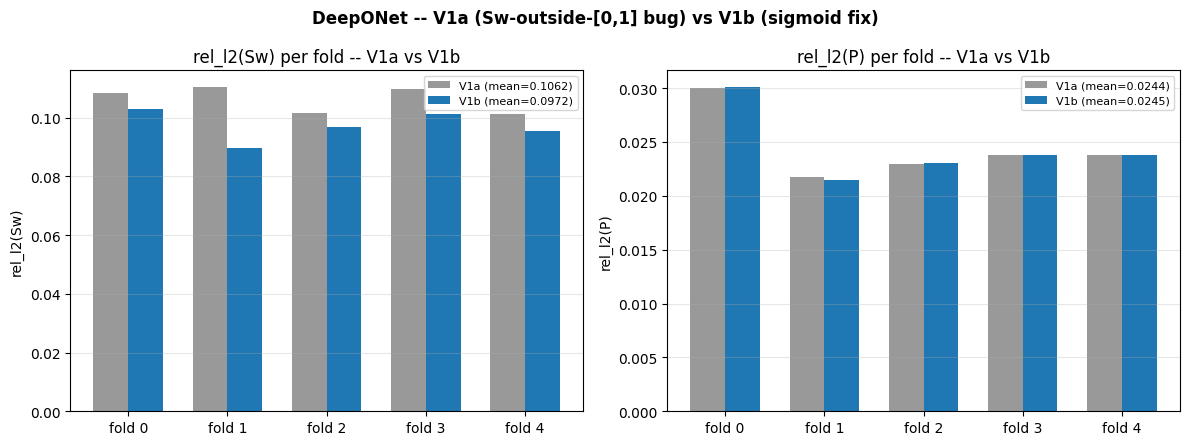

In [10]:
# -- CELL 9 - V1a vs V1b comparison: rel_l2(Sw) and rel_l2(P) per fold --
# V1a: historical numbers (resumen_V1a.json, run 2026-10-05T04:37) -- version archived in
# notebooks/.backup_pre_v1b/, no longer re-run; kept here fixed as a reference.
V1A_REL_L2_SW = [0.10836847126483917, 0.11054565757513046, 0.10160773992538452,
                 0.1096285954117775, 0.10108429938554764]
V1A_REL_L2_P = [0.030006563290953636, 0.021710090339183807, 0.022919707000255585,
                0.023796996101737022, 0.023794321343302727]

v1b_rel_l2_sw = [r["rel_l2_Sw"] for r in resultados_kfold]
v1b_rel_l2_p = [r["rel_l2_P"] for r in resultados_kfold]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(N_FOLDS)
width = 0.35
for ax, v1a_vals, v1b_vals, canal in zip(
    axes, [V1A_REL_L2_SW, V1A_REL_L2_P], [v1b_rel_l2_sw, v1b_rel_l2_p], ["Sw", "P"]
):
    ax.bar(x - width / 2, v1a_vals, width, label=f"V1a (mean={np.mean(v1a_vals):.4f})", color="#999999")
    ax.bar(x + width / 2, v1b_vals, width, label=f"V1b (mean={np.mean(v1b_vals):.4f})", color="#1f77b4")
    ax.set_xticks(x)
    ax.set_xticklabels([f"fold {k}" for k in range(N_FOLDS)])
    ax.set_ylabel(f"rel_l2({canal})")
    ax.set_title(f"rel_l2({canal}) per fold -- V1a vs V1b")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"{TECNICA_ID} -- V1a (Sw-outside-[0,1] bug) vs V1b (sigmoid fix)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

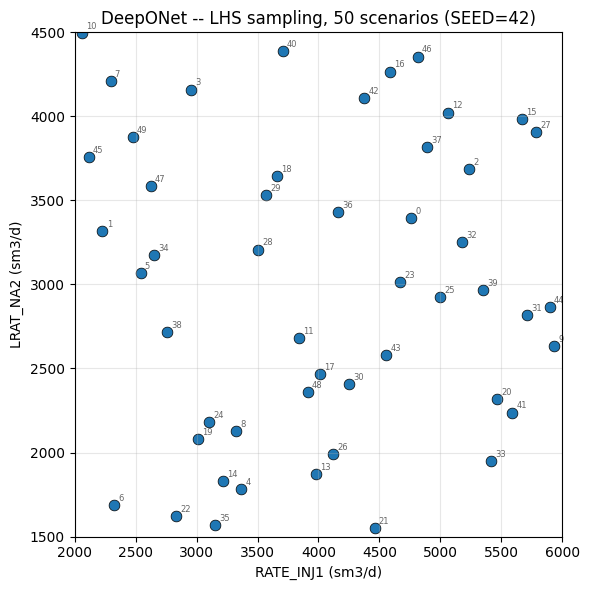

In [11]:
# -- CELL 10 - LHS sampling coverage: the 50 scenarios in (RATE_INJ1, LRAT_NA2) --
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(params[:, 0], params[:, 1], c="#1f77b4", s=60, edgecolors="k", linewidths=0.5)
for e in range(N_ESCENARIOS):
    ax.annotate(str(e), (params[e, 0], params[e, 1]), fontsize=6, alpha=0.6,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlim(*RATE_INJ1_RANGE)
ax.set_ylim(*LRAT_NA2_RANGE)
ax.set_xlabel("RATE_INJ1 (sm3/d)")
ax.set_ylabel("LRAT_NA2 (sm3/d)")
ax.set_title(f"{TECNICA_ID} -- LHS sampling, {N_ESCENARIOS} scenarios (SEED={SEED})")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Definition used: first t with Sw(NA2) > Sw0(NA2) + 0.02 (simple threshold, not the only possible one).
Scenarios with no breakthrough detected within the 5-year horizon: 0 of 50
Breakthrough -- min=1.66 years, max=2.58 years, mean=1.95 years


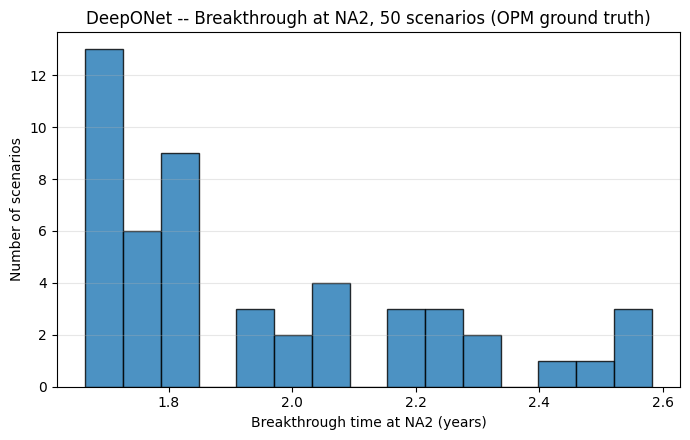

In [12]:
# -- CELL 11 - Breakthrough histogram at NA2 (threshold: Sw(NA2) > Sw0(NA2)+0.02) --
sw_na2 = swat[:, :, NA2_IJ[0], NA2_IJ[1]]  # (N_ESCENARIOS, N_T)
sw0_na2 = sw_na2[:, 0]
umbral = sw0_na2 + 0.02
supera = sw_na2 > umbral[:, None]
bt_idx = np.argmax(supera, axis=1)  # first index that satisfies it (0 if never satisfied)
nunca = ~supera.any(axis=1)
bt_years = time_days[bt_idx] / 365.25

print(f"Definition used: first t with Sw(NA2) > Sw0(NA2) + 0.02 (simple threshold, not the only possible one).")
print(f"Scenarios with no breakthrough detected within the 5-year horizon: {nunca.sum()} of {N_ESCENARIOS}")
if (~nunca).any():
    print(f"Breakthrough -- min={bt_years[~nunca].min():.2f} years, max={bt_years[~nunca].max():.2f} years, "
          f"mean={bt_years[~nunca].mean():.2f} years")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(bt_years[~nunca], bins=15, color="#1f77b4", edgecolor="k", alpha=0.8)
ax.set_xlabel("Breakthrough time at NA2 (years)")
ax.set_ylabel("Number of scenarios")
ax.set_title(f"{TECNICA_ID} -- Breakthrough at NA2, {N_ESCENARIOS} scenarios (OPM ground truth)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

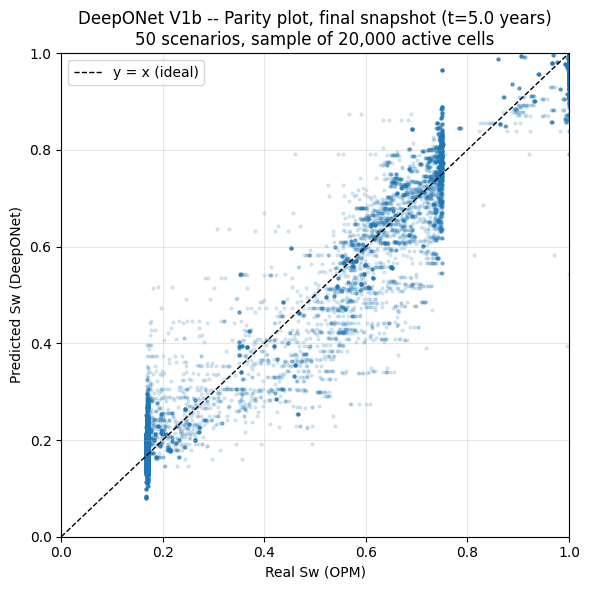

In [13]:
# -- CELL 12 - Parity plot: predicted Sw vs. real Sw (final snapshot, all scenarios) --
model_final.eval()
with torch.no_grad():
    pred_all = model_final(branch_in_t, t_hat_t)  # (N_ESCENARIOS, 2, N_T, NX, NY)

sw_pred_final = pred_all[:, 0, -1].cpu().numpy()[:, actnum]  # (N_ESCENARIOS, n_active)
sw_real_final = target[:, 0, -1][:, actnum]

# sample so as not to saturate the plot (50 scenarios x ~4698 active cells = ~235k points)
rng_plot = np.random.default_rng(SEED)
idx_muestra = rng_plot.choice(sw_pred_final.size, size=min(20000, sw_pred_final.size), replace=False)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sw_real_final.ravel()[idx_muestra], sw_pred_final.ravel()[idx_muestra],
           s=4, alpha=0.15, color="#1f77b4")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="y = x (ideal)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Real Sw (OPM)")
ax.set_ylabel("Predicted Sw (DeepONet)")
ax.set_title(f"{TECNICA_ID} {VERSION_ID} -- Parity plot, final snapshot (t={time_days[-1]/365.25:.1f} years)\n"
             f"{N_ESCENARIOS} scenarios, sample of {len(idx_muestra):,} active cells")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

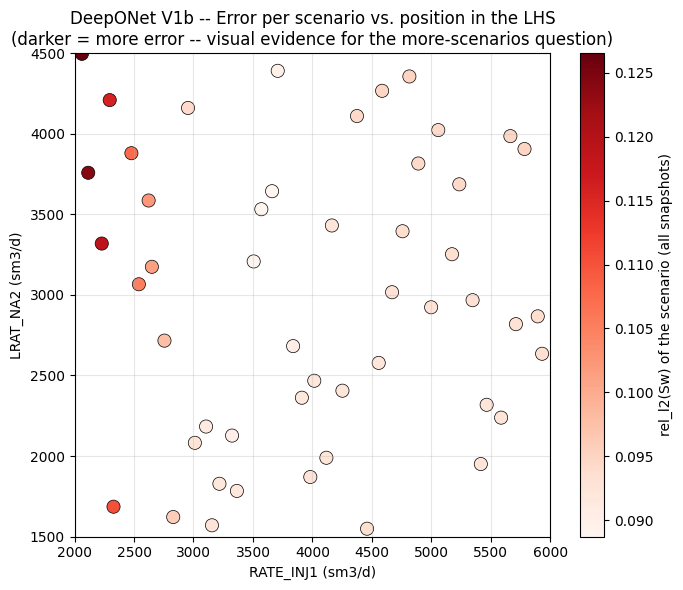

Error correlation vs RATE_INJ1: -0.577  |  error vs LRAT_NA2: 0.318
High correlation (|r| close to 1) suggests the error grows toward one end of the sampled
range (a sign of extrapolation) -- low correlation suggests it does not depend on position.


In [ ]:
# -- CELL 13 - Error per scenario vs. position in LHS space (edges vs. center) --
# Uses pred_all computed in CELL 12 (the forward pass over the 50 scenarios is not repeated).
sw_pred_np = pred_all[:, 0].cpu().numpy()  # (N_ESCENARIOS, N_T, NX, NY)
sw_real_np = target[:, 0]

err_por_escenario = np.array([
    np.linalg.norm((sw_real_np[e] - sw_pred_np[e])[:, actnum])
    / np.linalg.norm(sw_real_np[e][:, actnum])
    for e in range(N_ESCENARIOS)
])

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(params[:, 0], params[:, 1], c=err_por_escenario, cmap="Reds",
                 s=90, edgecolors="k", linewidths=0.5)
plt.colorbar(sc, ax=ax, label="rel_l2(Sw) of the scenario (all snapshots)")
ax.set_xlim(*RATE_INJ1_RANGE)
ax.set_ylim(*LRAT_NA2_RANGE)
ax.set_xlabel("RATE_INJ1 (sm3/d)")
ax.set_ylabel("LRAT_NA2 (sm3/d)")
ax.set_title(f"{TECNICA_ID} {VERSION_ID} -- Error per scenario vs. position in the LHS\n"
             f"(darker = more error -- visual evidence for the more-scenarios question)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr_x = np.corrcoef(params[:, 0], err_por_escenario)[0, 1]
corr_y = np.corrcoef(params[:, 1], err_por_escenario)[0, 1]
print(f"Error correlation vs RATE_INJ1: {corr_x:.3f}  |  error vs LRAT_NA2: {corr_y:.3f}")
print("High correlation (|r| close to 1) suggests the error grows toward one end of the sampled")
print("range (a sign of extrapolation) -- low correlation suggests it does not depend on position.")

## Notes / next steps

- The number that matters for the thesis is the k-fold from Section 5 (mean +/- std over 5 folds), not the single example in Section 7 (that scenario was already seen during the final model's training).
- If the k-fold `rel_l2(Sw)` is high, candidates to try (see tech-plan, explicitly out of scope for this V1): more branch capacity (more conv channels), more epochs, smaller `lr` if there is instability.
- Explicitly out of scope for this V1 (future work): FNO/KAN branch, KAN trunk, more scenarios, opening up the BHP axis.
- The saved checkpoint (`deeponet_V1a_unisim1.pt`) includes the normalization constants -- needed to predict on a new scenario without having to recompute them.